# Л3 — Рішення з ціною помилки

Модель класифікації дає ймовірність події, наприклад відмови обладнання. Щоб із цього вийшло рішення — висилати бригаду чи ні, — модель має вчитися на чесних даних, а поріг має враховувати ціну кожної помилки.

Ноутбук нижче проходить цей шлях на одній задачі, спрощено. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Intro to Machine Learning](https://www.kaggle.com/learn/intro-to-machine-learning) та [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning) з уроками про витік даних, pipelines і крос-валідацію.

Типовий шлях задачі класифікації (у дужках — кроки цього ноутбука):

- зрозуміти дані (1);
- перевірити, чи дані чесні: витік, зміщена вибірка, data drift (2–4);
- підготувати ознаки: кодування категорій, масштабування (5). У реальних проєктах ці перетворення збирають у pipeline, щоб до нових даних застосовувались ті самі кроки; тут вони написані вручну;
- розділити дані на навчальну й валідаційну частини (5). Часто замість однієї валідаційної частини беруть крос-валідацію; тут її немає;
- порівняти кілька моделей (6);
- підібрати гіперпараметри (7). Зазвичай це перебір за сіткою з крос-валідацією (`GridSearchCV`); тут лише одна крива для `alpha`;
- обрати поріг рішення під задачу (8);
- застосувати модель до нових даних (9) і далі стежити, чи не погіршилась вона з часом.

І головне: гарна метрика на валідації ще не гарантує, що модель працюватиме на нових даних. Якщо в даних є витік, зміщення чи зсув, модель виглядатиме добре, а рішення будуть поганими.

Інші часті проблеми даних, про які варто пам'ятати:

- **незбалансовані класи** — подія рідкісна, і частка правильних відповідей оманлива. Тут відмов 5–9%, тому моделі порівнюють за PR-AUC (крок 6);
- **замало даних** — модель запам'ятовує навчальні приклади замість закономірності; близьке явище видно на кривій перенавчання (крок 7);
- **пропуски й помилки в даних** — Л1;
- **помилки в мітках** — частину об'єктів позначено неправильно, і модель вчиться на цих помилках; тут цього немає;
- **зв'язок без причини** — ознака пов'язана з ціллю через третій чинник, а не напряму; Л2.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних, вартості й таблиця пасток — у `README.md`.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

## 1. Завантаження даних

Спершу подивіться, що всередині файлів: розмірність, колонки, типи й частку відмов у `train`. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

Вартості свого варіанта впишіть із таблиці в `README.md`: від них залежить правило рішення в кроці 8.

In [40]:
COST_VISIT = 5500
COST_FAILURE = 50000

# TODO: завантажте registry.csv, train.csv і test.csv свого варіанта з папки variants/<варіант>/ і виведіть частку failed у train
registry = pd.read_csv("registry.csv")
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

display(registry)
print(registry.dtypes)
print("Розмірність registry.csv:", registry.shape)
display(train)
print(train.dtypes)
print("Розмірність train.csv:", train.shape)
print("Частка відмов у train:", train["failed"].mean())
display(test)
print(test.dtypes)
print("Розмірність test.csv:", test.shape)


,object_id,cohort,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor
0,EQ100001,history,transformer,kv35,centre,1989,2018,1
1,EQ100002,history,transformer,kv10,centre,1998,2019,1
2,EQ100003,history,transformer,kv35,west,1984,2020,1
3,EQ100004,history,transformer,kv6,south,1993,2016,0
4,EQ100005,history,meter_unit,kv35,west,2017,2022,0
...,...,...,...,...,...,...,...,...
5995,EQ105996,current,transformer,kv10,centre,1978,2025,0
5996,EQ105997,current,meter_unit,kv10,centre,1996,2022,0
5997,EQ105998,history,transformer,kv35,west,1992,2024,1
5998,EQ105999,history,transformer,kv35,north,2005,2018,1


object_id               str
cohort                  str
equipment_type          str
voltage_class           str
region                  str
install_year          int64
last_overhaul_year    int64
outdoor               int64
dtype: object
Розмірність registry.csv: (6000, 8)


,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,...,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,failed,work_order_opened
0,EQ100001,97.955,13.587,0.8782,0.7907,13.824,0.961,13.805,31.829,5.912,...,0.3249,0.1411,transformer,kv35,centre,1989,2018,1,0,0
1,EQ100002,88.522,13.235,0.8699,0.8090,23.949,2.263,24.295,31.070,6.598,...,0.3510,0.2705,transformer,kv10,centre,1998,2019,1,0,0
2,EQ100003,70.073,7.421,0.9042,0.8228,17.280,1.245,17.110,38.119,7.914,...,0.5440,0.2466,transformer,kv35,west,1984,2020,1,0,0
3,EQ100004,74.856,8.882,0.8939,0.8132,17.378,1.162,17.490,53.300,10.921,...,0.7120,0.2322,transformer,kv6,south,1993,2016,0,0,0
4,EQ100005,35.937,3.923,0.9016,0.8080,14.518,1.089,14.475,59.870,13.135,...,1.6660,0.4040,meter_unit,kv35,west,2017,2022,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3921,EQ105993,28.981,4.024,0.8781,0.7777,11.275,0.728,11.275,35.441,7.267,...,1.2229,0.3890,meter_unit,kv6,south,1982,2018,1,0,0
3922,EQ105995,40.361,5.687,0.8765,0.7900,16.374,1.213,16.325,58.720,12.398,...,1.4549,0.4057,switchgear,kv10,south,2006,2018,1,0,0
3923,EQ105998,72.994,11.604,0.8628,0.7689,19.555,1.711,20.055,27.716,5.908,...,0.3797,0.2679,transformer,kv35,west,1992,2024,1,0,0
3924,EQ105999,60.702,8.810,0.8733,0.7934,15.858,1.255,15.835,28.761,5.347,...,0.4738,0.2612,transformer,kv35,north,2005,2018,1,0,0


object_id                 str
load_mean             float64
load_std              float64
load_stability        float64
load_weekend_ratio    float64
temp_rise_mean        float64
temp_rise_std         float64
temp_rise_median      float64
pd_mean               float64
pd_std                float64
pd_stability          float64
pd_per_load           float64
temp_per_load         float64
equipment_type            str
voltage_class             str
region                    str
install_year            int64
last_overhaul_year      int64
outdoor                 int64
failed                  int64
work_order_opened       int64
dtype: object
Розмірність train.csv: (3926, 21)
Частка відмов у train: 0.06826286296484972


,object_id,load_mean,load_std,load_stability,load_weekend_ratio,temp_rise_mean,temp_rise_std,temp_rise_median,pd_mean,pd_std,pd_stability,pd_per_load,temp_per_load,equipment_type,voltage_class,region,install_year,last_overhaul_year,outdoor,work_order_opened
0,EQ100006,77.957,8.736,0.8992,0.8086,30.840,2.935,31.820,70.176,15.080,0.8231,0.9002,0.3956,transformer,kv6,north,2014,2023,1,0
1,EQ100007,31.036,4.484,0.8738,0.7882,13.402,0.844,13.560,47.529,8.775,0.8441,1.5314,0.4318,meter_unit,kv6,centre,2020,2020,0,0
2,EQ100013,62.377,7.789,0.8890,0.7965,15.845,1.182,15.970,33.062,6.222,0.8416,0.5300,0.2540,transformer,kv35,north,1999,2025,1,0
3,EQ100014,40.550,5.794,0.8750,0.7818,20.912,1.482,20.930,74.380,14.930,0.8328,1.8343,0.5157,switchgear,kv35,west,1984,2016,0,0
4,EQ100020,41.043,5.581,0.8803,0.7942,14.411,0.802,14.455,44.033,8.890,0.8320,1.0729,0.3511,meter_unit,kv10,centre,1991,2015,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2069,EQ105989,59.942,8.032,0.8818,0.7814,16.500,1.339,16.550,60.230,14.067,0.8107,1.0048,0.2753,transformer,kv10,west,2012,2018,1,0
2070,EQ105991,41.580,6.193,0.8704,0.7912,10.192,0.578,10.250,20.313,3.590,0.8498,0.4885,0.2451,switchgear,kv35,west,1996,2018,0,0
2071,EQ105994,36.040,4.907,0.8802,0.7925,10.212,0.517,10.250,26.221,5.348,0.8306,0.7276,0.2834,switchgear,kv10,centre,1978,2016,1,0
2072,EQ105996,73.742,8.576,0.8958,0.8479,22.701,2.040,23.095,33.182,6.907,0.8277,0.4500,0.3078,transformer,kv10,centre,1978,2025,0,0


object_id                 str
load_mean             float64
load_std              float64
load_stability        float64
load_weekend_ratio    float64
temp_rise_mean        float64
temp_rise_std         float64
temp_rise_median      float64
pd_mean               float64
pd_std                float64
pd_stability          float64
pd_per_load           float64
temp_per_load         float64
equipment_type            str
voltage_class             str
region                    str
install_year            int64
last_overhaul_year      int64
outdoor                 int64
work_order_opened       int64
dtype: object
Розмірність test.csv: (2074, 20)


## 2. Витік (M-1)

Витік (data leakage) — колонка, значення якої стає відомим лише після того, що ми хочемо передбачити. Наприклад, у даних про відмови може бути колонка «вартість ремонту». Вона дуже точно «передбачає» відмову: ремонтують саме те, що зламалося. Але вартість ремонту з'являється вже після відмови, а рішення ухвалюють раніше, коли об'єкт ще працює й цього значення немає. Модель, навчена на такій колонці, на навчальних даних виглядає чудово, а на нових об'єктах не працює. Такі колонки прибирають.

Не завжди відомо, коли заповнюють кожну колонку, тож витік шукають за ознакою «надто добре вгадує». Для кожної колонки окремо рахують **ROC AUC** — ймовірність того, що у випадкового об'єкта, який відмовив, значення колонки більше, ніж у випадкового справного. 0.5 — колонка не відрізняє їх зовсім, як підкидання монети; 1 — відрізняє ідеально. Звичайна ознака на кшталт температури чи навантаження так точно не вгадує. Колонку з AUC понад 0.9 тут вважають витоком. У реальному проєкті висока AUC — привід з'ясувати, коли колонку заповнюють.

1. Для кожної числової колонки `train`, крім `failed`, порахуйте `roc_auc_score(train["failed"], колонка)`. Якщо AUC менше 0.5, візьміть 1 − AUC: колонка пов'язана з відмовою навпаки, у тих, що відмовили, значення менші.
2. Виведіть AUC усіх колонок від більшого до меншого.
3. Колонки з AUC більше 0.9 приберіть із `train` і `test`.

Можуть допомогти `select_dtypes("number")`, `sort_values` і `drop(columns=...)`.

In [41]:
# TODO: M-1
auc_scores = {}

num_columns = train.select_dtypes(include="number").columns

for i in num_columns:
    if i == "failed": continue

    auc = roc_auc_score(train["failed"], train[i])
    if auc < 0.5:
        auc = 1 - auc
    auc_scores.update({i : auc})

sorted_scores = sorted(auc_scores.items(), key=lambda x: x[1], reverse=True)

display(sorted_scores)

drop_cols = []
for i in sorted_scores:
    if i[1] > 0.9:
        drop_cols.append(i[0])

train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)



[('work_order_opened', 0.9655835094619848),
 ('temp_rise_mean', 0.7535451841394449),
 ('temp_rise_median', 0.7529428445525245),
 ('temp_rise_std', 0.7465119386664272),
 ('pd_mean', 0.7127115583917483),
 ('pd_std', 0.7098028855177366),
 ('temp_per_load', 0.6661682021820912),
 ('pd_per_load', 0.618145263295333),
 ('load_mean', 0.5938043176680838),
 ('load_std', 0.587815603502444),
 ('install_year', 0.5547879111821973),
 ('outdoor', 0.5330088213933069),
 ('last_overhaul_year', 0.5231806386329696),
 ('load_weekend_ratio', 0.5064043845833708),
 ('pd_stability', 0.5020763119884448),
 ('load_stability', 0.5000326416033556)]

## 3. Зміщена вибірка (M-2)

Завжди треба враховувати, як збирали дані. Наприклад, лікарня має дані переважно про людей, які прийшли з підозрою на хворобу: здорові приходять туди набагато рідше. Тож хворих у таких даних набагато більше, ніж серед усіх людей. Таке зміщення вибірки (selection bias) буває й в інших задачах: результат відомий не для всіх об'єктів, а переважно для тих, що вже викликали підозру.

Модель на таких даних усе ще може навчитися відрізняти ризикові об'єкти від решти. Але числа, пораховані на зміщеній вибірці, — частку подій, точність, ефект рішення — не можна переносити на всі об'єкти: вони будуть спотворені.

У цій задачі `registry.csv` містить усі об'єкти, а `train.csv` — лише ті об'єкти `history`, для яких відомо, чи вони відмовили.

Поділіть кількість рядків `train` на кількість об'єктів `registry` з `cohort == "history"` і виведіть частку; менше 0.9 — вибірка зміщена. Тоді виведіть ще середній `install_year` об'єктів `history`, що є в `train`, і об'єктів `history`, яких у `train` немає. Може допомогти `isin`.

У коді після цього нічого не змінюється: рішення будується так само, але частку відмов і ефект на валідації не можна переносити на всі об'єкти.

In [42]:
# TODO: M-2
history = registry[registry["cohort"] == "history"]

moved_part = len(train) / len(history)

print("Частка зміщення:", moved_part)

if moved_part < 0.9:
    print("Вибірка зміщена")
else:
    print("Вибірка не зміщена")

in_train = history[history["object_id"].isin(train["object_id"])]
not_in_train = history[~history["object_id"].isin(train["object_id"])]

print("Cередній 'install_year' об'єктів 'history', що є в 'train':", in_train["install_year"].mean())
print("Cередній 'install_year' об'єктів 'history', що немає в 'train':", not_in_train["install_year"].mean())


Частка зміщення: 1.0
Вибірка не зміщена
Cередній 'install_year' об'єктів 'history', що є в 'train': 1998.8927661742232
Cередній 'install_year' об'єктів 'history', що немає в 'train': nan


## 4. Зсув у часі (M-3)

Властивості об'єктів змінюються з часом: люди старішають, обладнання зношується, датчик після калібрування чи заміни починає показувати інакше. Тому дані різних періодів можуть відрізнятися. Це називають **data drift** (зсув даних). Коли ж змінюється сам зв'язок ознак із ціллю, це **concept drift**; тут його немає.

Проблема виникає, коли зсув не врахували. Модель вивчила, що звичайна температура — 40 °C, а в нових даних датчик показує 45 °C для таких самих об'єктів. Модель побачить «гарячіші» об'єкти й помилятиметься, хоча нічого не змінилося.

**Як помітити:** порівняти розподіл ознак у навчальних і нових даних — середні, гістограми. Тут зсув середнього міряють у стандартних відхиленнях train: 0.5 — половина звичайного розкиду між об'єктами. Зсув рахують зі знаком: від'ємний означає, що в нових даних значення нижчі.

**Як боротися** — залежить від причини:

- **змінилася шкала вимірювання** (калібрування, інший датчик), а об'єкти ті самі — ознаки зводять до однієї шкали, наприклад стандартизують окремо в кожному періоді. Середнє стає 0, відхилення 1, а порядок об'єктів — хто гарячіший за кого — лишається;
- **змінилися самі об'єкти** — таке вирівнювання стерло б справжні зміни. Тоді модель перенавчають на свіжих даних і регулярно перевіряють її якість.

У цій задачі `train.csv` описує перший період, `test.csv` — другий. Якщо зсув є, він — у шкалі температурного датчика, тож підходить перший спосіб.

1. Виведіть зсув зі знаком: (середнє `temp_rise_mean` у test − середнє в train) / стандартне відхилення `temp_rise_mean` у train. Відхилення — `.std()` з pandas.
2. Якщо зсув більший за 0.5, стандартизуйте колонки `temp`: у train — середнім і відхиленням train, у test — середнім і відхиленням test. Якщо стандартизувати test за train, зсув лишиться.

In [43]:
temp = ["temp_rise_mean", "temp_rise_std", "temp_rise_median", "temp_per_load"]

# TODO: M-3 — зсув і, якщо він більший за 0.5, стандартизація temp окремо в train і в test

temp_shift = (test["temp_rise_mean"].mean() - train["temp_rise_mean"].mean()) / train["temp_rise_mean"].std()

print("Розрахований зсув:", temp_shift)

if abs(temp_shift) > 0.5:
    print("Зсув виявлено")
    test[temp] = (test[temp]-test[temp].mean()) / test[temp].std()
    train[temp] = (train[temp]-train[temp].mean()) / train[temp].std()
else:
    print("Зсув не виявлено")


Розрахований зсув: -0.028322182117969937
Зсув не виявлено


## 5. Ознаки й поділ

Моделі працюють із числами, тому категорійні колонки кодують **one-hot**: окрема колонка 0/1 на кожне значення. Порядкових номерів категоріям не дають, бо `north` не «більше» за `south`.

**Валідаційна частина.** Щоб зрозуміти, як модель працюватиме на нових об'єктах, її перевіряють на даних, яких вона не бачила під час навчання. Для цього частину `train` відкладають убік — це валідаційна частина. На ній і порівнюють моделі: модель, що просто запам'ятала навчальні об'єкти, на навчальних даних виглядатиме ідеально, а на валідаційних — ні.

Валідаційна частина має бути схожою на дані, до яких модель застосовуватимуть. Відмови рідкісні, тож при випадковому поділі частка відмов у ній може помітно відрізнятися від навчальної, а в малому наборі даних відмов там може не виявитися зовсім, і оцінити модель стане неможливо. `stratify=y` зберігає однакову частку відмов в обох частинах.

**Масштабування.** Ознаки мають різні одиниці й розміри: `load_mean` — від 15 до 148 А, а `load_stability` — від 0.85 до 0.91. Метод опорних векторів, найближчі сусіди й перцептрон рахують відстані чи зважені суми, тож для них різниця навантаження в 100 переважить різницю стабільності в 0.05, навіть якщо стабільність важливіша. Тому ознаки стандартизують: середнє 0, стандартне відхилення 1. Дереву рішень і наївному Баєсу масштаб не заважає. Середні й відхилення беруть лише з навчальної частини: якщо взяти їх з усіх даних, валідаційна частина вплине на навчання — це теж витік, як у кроці 2.

1. Зберіть ознаки через `pd.get_dummies(..., columns=categorical, dtype=float)`: `X` — з `train` без `object_id` і `failed`, `X_test` — з `test` без `object_id`. Колонки `X_test` мають іти в тому самому порядку, що в `X`: `X_test[X.columns]`.
2. `y` — колонка `failed`.
3. Поділ і стандартизацію задано нижче: `StandardScaler` навчається лише на `X_tr` і тим самим перетворенням застосовується до `X_va` і `X_test`.

In [44]:
categorical = ["equipment_type", "voltage_class", "region"]

# TODO: X, X_test і y
X = pd.get_dummies(train.drop(columns=["object_id", "failed"]), columns=categorical, dtype=float)
X_test = pd.get_dummies(test.drop(columns=["object_id"]), columns=categorical, dtype=float)
X_test = X_test[X.columns]
y = train["failed"]

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

scaler = StandardScaler().fit(X_tr)
X_tr, X_va, X_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_test)

## 6. П'ять моделей

**Як порівнювати.** Звична метрика — **accuracy**, частка правильних відповідей. При рідкісних подіях вона оманлива: якщо відмов 8%, модель, яка завжди каже «не відмовить», має accuracy 92%, але не знаходить жодної відмови.

Тому тут порівнюють інакше. Модель упорядковує об'єкти від найризикованішого до найспокійнішого. Якщо брати об'єкти згори списку, можна рахувати **precision** — яка частка взятих справді відмовила, і **recall** — яку частку всіх відмов уже знайдено. **PR-AUC** (`average_precision_score`) — середня precision, поки список росте від першої знайденої відмови до останньої. 1 — усі відмови стоять на самому верху списку; якщо порядок випадковий, PR-AUC дорівнює частці відмов. Тому PR-AUC завжди порівнюють із часткою відмов.

| Модель | Як оцінює ймовірність відмови |
|---|---|
| дерево рішень | ділить об'єкти порогами ознак; ймовірність — частка відмов у листку. `max_depth` обмежує кількість поділів |
| метод опорних векторів | шукає межу з найширшим проміжком між класами; сам дає лише відстань до межі, а `CalibratedClassifierCV` перетворює її на ймовірність |
| найближчі сусіди | частка відмов серед `n_neighbors` найближчих об'єктів навчальної частини |
| наївний Баєс | формула Баєса за припущення, що ознаки незалежні |
| багатошаровий перцептрон | прихований шар із 32 нейронів: кожен зважує ознаки й пропускає суму через функцію активації ReLU; вихідний нейрон дає ймовірність. Ваги підбирає зворотне поширення помилки, `alpha` — штраф за великі ваги |

Якщо навчальна PR-AUC набагато вища за валідаційну, модель запам'ятала навчальні об'єкти, а не навчилася розпізнавати ризик. Це **перенавчання** (overfitting), про нього — крок 7.

Далі рішення ухвалює перцептрон: на ньому в кроці 7 показано перенавчання, і рецепт однаковий для всіх варіантів. На ваших даних інша модель може бути кращою — це нормально, у звіті просто назвіть її. У реальному проєкті для рішення взяли б найкращу модель на валідації.

1. Навчіть кожну модель зі словника `models` на `X_tr`, `y_tr` і виведіть таблицю: модель, PR-AUC на навчальній і на валідаційній частині. PR-AUC рахуйте за ймовірностями `predict_proba(...)[:, 1]`. Функція, що рахує PR-AUC моделі на обох частинах, знадобиться ще в кроці 7.
2. Виведіть частку відмов у `y_va`.
3. Знайдіть найкращу модель на валідаційній частині й порівняйте її PR-AUC і PR-AUC перцептрона з часткою відмов — це відповідь для питання 2 звіту.

In [45]:
models = {
    "дерево рішень": DecisionTreeClassifier(max_depth=5, random_state=0),
    "опорні вектори": CalibratedClassifierCV(SVC(), ensemble=False),
    "найближчі сусіди": KNeighborsClassifier(n_neighbors=25),
    "наївний Баєс": GaussianNB(),
    "перцептрон": MLPClassifier(hidden_layer_sizes=(32,), alpha=1.0, max_iter=1000, random_state=0),
}

# TODO: навчіть моделі й виведіть таблицю PR-AUC і частку відмов у y_va
pr_auc_table = []
for name, model in models.items():
    model.fit(X_tr, y_tr)
    pr_auc_train = average_precision_score(y_tr, model.predict_proba(X_tr)[:, 1])
    pr_auc_val = average_precision_score(y_va, model.predict_proba(X_va)[:, 1])
    pr_auc_table.append({"модель": name, "PR-AUC train": pr_auc_train, "PR-AUC valid": pr_auc_val})

pr_auc_table = pd.DataFrame(pr_auc_table).set_index("модель")
y_mean = y_va.mean()

display(pr_auc_table)
print("Частка відмов y_va:", y_mean)

top2 = pr_auc_table["PR-AUC valid"].nlargest(2)

print("Найкраща на валідації:", top2.index[0], top2.iloc[0], "; Відношення до частки відмов:", top2.iloc[0]/y_mean)
print("Друга найкраща на валідації:", top2.index[1], top2.iloc[1], "; Відношення до частки відмов:", top2.iloc[1]/y_mean)
print("Перцептрон:", pr_auc_table.loc["перцептрон", "PR-AUC valid"], "; Відношення до частки відмов:", pr_auc_table.loc["перцептрон", "PR-AUC valid"]/y_mean)


,PR-AUC train,PR-AUC valid
модель,,
дерево рішень,0.410055,0.175586
опорні вектори,0.806289,0.213967
найближчі сусіди,0.320309,0.217951
наївний Баєс,0.289483,0.277475
перцептрон,0.407716,0.277551


Частка відмов y_va: 0.06822810590631365
Найкраща на валідації: перцептрон 0.27755081707015905 ; Відношення до частки відмов: 4.067983617356659
Друга найкраща на валідації: наївний Баєс 0.27747541296801587 ; Відношення до частки відмов: 4.0668784408148
Перцептрон: 0.27755081707015905 ; Відношення до частки відмов: 4.067983617356659


## 7. Перенавчання перцептрона

**Перенавчання** — модель запам'ятовує навчальні приклади разом із їхнім шумом, замість того щоб знайти загальну закономірність. Як студент, що завчив відповіді до конкретних білетів: на цих білетах — відмінно, на нових — погано. Ознака перенавчання: навчальна метрика висока, валідаційна — значно нижча.

Один зі способів боротьби — **регуляризація**: штраф, що змушує модель бути простішою. У перцептрона це `alpha` — штраф за великі ваги. Із малим `alpha` мережа підлаштовує ваги під кожен навчальний об'єкт, і її ймовірності стають надто впевненими, близькими до 0 або 1. Правилу з кроку 8 потрібні правдоподібні ймовірності, тому для рішення взято `alpha=1`. У реальному проєкті `alpha` підбирали б перебором (див. вступ).

Якщо при малих `alpha` з'явиться попередження `ConvergenceWarning`, воно означає, що оптимізатор не встиг зійтися за `max_iter` ітерацій: мережа все ще підганяється під навчальні об'єкти.

1. Для кожного `alpha` зі списку навчіть такий самий перцептрон, як у кроці 6, але з цим `alpha`. Перцептрон із кроку 6 не перезаписуйте: він потрібен у кроках 8–9.
2. Виведіть таблицю «alpha, PR-AUC на навчальній і на валідаційній частині» і побудуйте обидві криві на одному графіку; вісь `alpha` — логарифмічна (`plt.xscale("log")`).
3. Прочитайте криву: що відбувається з навчальною і валідаційною PR-AUC, коли `alpha` зменшується, і при якому `alpha` розрив найбільший — це відповідь для питання 2 звіту.

E:\DataAnalysis\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
E:\DataAnalysis\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
E:\DataAnalysis\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,alpha,PR-AUC train,PR-AUC valid
0,0.0001,0.856801,0.233886
1,0.0010,0.865600,0.224905
2,0.0100,0.866686,0.229197
3,0.1000,0.657847,0.260755
4,1.0000,0.407716,0.277551


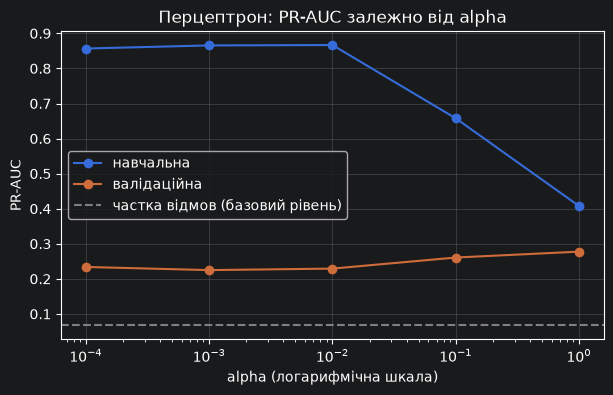

In [46]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]

# TODO: таблиця й графік PR-AUC від alpha

al_percep = []

for i in alphas:
    percep = MLPClassifier(hidden_layer_sizes=(32,), alpha=i, max_iter=1000, random_state=0)
    percep.fit(X_tr, y_tr)
    pr_auc_train = average_precision_score(y_tr, percep.predict_proba(X_tr)[:, 1])
    pr_auc_val = average_precision_score(y_va, percep.predict_proba(X_va)[:, 1])
    al_percep.append({"alpha": i, "PR-AUC train": pr_auc_train, "PR-AUC valid": pr_auc_val})

al_percep = pd.DataFrame(al_percep)

display(al_percep)

plt.figure(figsize=(7, 4))
plt.plot(al_percep["alpha"], al_percep["PR-AUC train"], marker="o", label="навчальна")
plt.plot(al_percep["alpha"], al_percep["PR-AUC valid"], marker="o", label="валідаційна")
plt.axhline(y_va.mean(), color="gray", linestyle="--", label="частка відмов (базовий рівень)")
plt.xscale("log")
plt.xlabel("alpha (логарифмічна шкала)")
plt.ylabel("PR-AUC")
plt.title("Перцептрон: PR-AUC залежно від alpha")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 8. Правило рішення

Модель дає ймовірність, а диспетчер має вирішити «їхати чи ні». Звичний поріг 0.5 означає «їхати, якщо відмова ймовірніша, ніж її відсутність». Але помилки коштують по-різному: зайвий виїзд — `COST_VISIT`, пропущена відмова — `COST_FAILURE`, у десятки разів дорожче. Тож виїзд виправданий і за значно меншої ймовірності.

Не поїхати до об'єкта з ймовірністю відмови p — у середньому втратити p · `COST_FAILURE`. Виїзд окупається, коли p · `COST_FAILURE` не менше за `COST_VISIT`, тобто коли p не менша за поріг `COST_VISIT / COST_FAILURE`.

Правило працює, лише якщо ймовірностям можна вірити: серед об'єктів з ймовірністю 0.1 має справді відмовляти близько 10%. Це називають **калібруванням** (calibration). Перша проста перевірка — середня ймовірність має бути близькою до частки відмов.

Ефект рішення — скільки гривень воно зберігає проти «нікого не перевіряти»:

- витрати «нікого не перевіряти» = кількість відмов · `COST_FAILURE`;
- витрати рішення = кількість виїздів · `COST_VISIT` + кількість об'єктів, що відмовили і до яких не виїхали, · `COST_FAILURE`;
- ефект = перше − друге.

1. Порахуйте поріг `COST_VISIT / COST_FAILURE` і ймовірності перцептрона з кроку 6 на `X_va`.
2. Виведіть поріг, середню ймовірність і частку відмов у `y_va`.
3. Виведіть таблицю для трьох правил — поріг з вартостей, поріг 0.5, перевірити всіх: скільки об'єктів на виїзд і ефект у гривнях. Ефект для трьох правил — одна функція від рішень, а не три копії формули. `y_va` після поділу має перемішаний індекс, тож рішення порівнюйте з `y_va.to_numpy()`.
4. Порівняйте три правила: яке зберігає найбільше і чому поріг 0.5 тут поганий — це відповідь для питання 3 звіту.

In [47]:
# TODO: поріг, ймовірності й таблиця трьох правил

percep_6 = models["перцептрон"]
prob = percep_6.predict_proba(X_va)[:, 1]
border = COST_VISIT / COST_FAILURE

y_stable = y_va.to_numpy()

print("Поріг COST_VISIT / COST_FAILURE:", border)
print("Середня ймовірність відмови:", prob.mean())
print("Частка відмов у y_va:", y_va.mean())

rules = {
    "поріг з вартостей": prob >= border,
    "поріг 0.5":         prob >= 0.5,
    "перевірити всіх":   np.ones_like(prob, dtype=bool),
}

def tester(decisions):
    failed_not_checked = (y_stable & ~decisions).sum()
    unchecked_cost = y_stable.sum() * COST_FAILURE
    decision_cost = (decisions.sum() * COST_VISIT) + (failed_not_checked * COST_FAILURE)
    print(decisions.sum() * COST_VISIT)
    print(decisions.sum())
    effect = unchecked_cost - decision_cost
    return effect

results = []

for i in rules.items():
    res = tester(i[1])
    results.append({"правило": i[0], "виїзди": i[1].sum(), "ефект, грн":res})

results = pd.DataFrame(results)
display(results)

Поріг COST_VISIT / COST_FAILURE: 0.11
Середня ймовірність відмови: 0.0712447912393035
Частка відмов у y_va: 0.06822810590631365
836000
152
66000
12
5401000
982


,правило,виїзди,"ефект, грн"
0,поріг з вартостей,152,714000
1,поріг 0.5,12,334000
2,перевірити всіх,982,-2051000


## 9. Рішення й самоперевірка

Порахуйте ймовірності перцептрона з кроку 6 на `X_te` і рішення: 1, якщо ймовірність не менша за поріг з вартостей, інакше 0. Це рішення ви здаєте: викладач порахує, скільки гривень воно зберегло б на справжніх результатах об'єктів test.

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [48]:
# TODO: рішення для test
percep_6 = models["перцептрон"]
prob = percep_6.predict_proba(X_te)[:, 1]
border = COST_VISIT / COST_FAILURE

decision = (prob >= border).astype(int)

submission = pd.DataFrame({"object_id": test["object_id"], "decision": decision})

assert (COST_VISIT, COST_FAILURE) in [(1800, 60000), (2750, 50000), (4080, 48000), (5500, 50000)], "вартості — з таблиці README"
assert all(max(a, 1 - a) <= 0.9 for a in (roc_auc_score(y, X[c]) for c in X.columns)), "в ознаках лишилася колонка з AUC понад 0.9"
assert list(X_test.columns) == list(X.columns), "колонки X_test мають збігатися з X"
assert len(X_va) == int(np.ceil(len(train) * 0.25)), "валідаційна частина — 25% train"
assert np.allclose(np.mean(X_tr, axis=0), 0) and np.allclose(np.std(X_tr, axis=0), 1), "X_tr не стандартизовано"
assert len(submission) == len(test) and submission["object_id"].is_unique, "має бути рядок на кожен об'єкт test"
assert pd.api.types.is_integer_dtype(submission["decision"]) and submission["decision"].isin([0, 1]).all(), "decision — цілі 0 або 1, а не True/False"
assert 0.02 <= submission["decision"].mean() <= 0.9, "на виїзд менше 2% або більше 90% об'єктів: перевірте поріг"

submission.to_csv("submission.csv", index=False)
print("усе гаразд: на виїзд", int(submission["decision"].sum()), "з", len(submission))

усе гаразд: на виїзд 239 з 2074
